# Learning curve

> Kex test scores on Fukushima against the number of training samples, for the Fukushima-only and fully fine-tuned CNNs and for ridge regressions on the spectra and on the pretrained model's block 4

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from soilspecdata.all import load_ossl
from ossl_fuku_transfer.data import *
from ossl_fuku_transfer.transfer import *
from ossl_fuku_transfer.inside import layer_features, probe

/Users/franckalbinet/pro/dev/soilspec/ossl-fuku-transfer/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Every code cell reads OSSL or the Fukushima data, and is marked `#| fukudata`. The outputs come from a local run on an Apple silicon GPU (MPS).

## Data and models

The data and preprocessing are those of `03_kex`. Of the 1,388 Fukushima spectra, 341 form the fixed test set and 1,047 are available for training:

In [ ]:
#| fukudata
om = load_ossl().mir(wmin=shared_wns[0], wmax=shared_wns[-1])
Xo, yo, _ = om.xy('k.ext_usda.a725_cmolc.kg')
yo = np.log1p(yo.ravel())
fuku = load_fuku()
fuku.source = fuku.source.assign(target=fuku.source['soil_ex_K2O'] / mg_k2o_per_cmolc)
Xf, yf, idf = fuku.xy('target')
yf = np.log1p(yf.ravel())
is_test = np.isin(idf, cs137_split()[1])
yt = yf[is_test]
pipe = preprocessings()['snv_d1']
Xo_d, Xf_d = pipe.fit_transform(Xo), pipe.transform(Xf)
int((~is_test).sum()), int(is_test.sum())

(1047, 341)

Four models:

- `Fukushima only`: the CNN from random weights, 40 epochs at a learning rate of 3·10⁻³;
- `fully fine-tuned`: the CNN from the saved OSSL model, 20 epochs at 3·10⁻³;
- `ridge, block 4`: a ridge regression on block 4 of the frozen OSSL model, the best layer in `07_inside_transfer`;
- `ridge, spectra`: a ridge regression on the preprocessed spectra.

The CNN schedules are those that cross-validation chose in `03_kex` on all 1,047 training samples, and stay fixed for every size. With fewer samples, a fixed number of epochs means fewer training steps. The CNNs keep a tenth of each subset for validation, as `fuku_dls` does, and the ridge regressions use the whole subset.

In [ ]:
#| fukudata
pretrained = load_pretrained('ossl_kex_snv_d1')
start = {'Fukushima only': None, 'fully fine-tuned': pretrained}
schedules = {'Fukushima only': (40, 3e-3), 'fully fine-tuned': (20, 3e-3)}
ridge_X = {'ridge, block 4': layer_features(pretrained, Xf_d)['block 4'], 'ridge, spectra': Xf_d}
{k: v.shape for k, v in ridge_X.items()}

{'ridge, block 4': (1388, 2560), 'ridge, spectra': (1388, 1675)}

## Curve

Five training sizes, each drawn five times with a different seed. All models of a seed use the same subset, the one `subset_preds` draws. At 1,047 the subset is the whole training set, so the seeds only change the validation split and the CNNs' initialisation, and the ridge regressions give the same result for every seed. The results are saved in `model_dir()` and loaded on later runs:

In [ ]:
#| fukudata
sizes, seeds = [100, 200, 400, 700, 1047], range(5)
fn = model_dir()/'curve_kex.csv'
if fn.exists(): curve = pd.read_csv(fn)
else:
    rows = []
    for n in sizes:
        for s in seeds:
            sub = np.random.RandomState(s).choice(np.flatnonzero(~is_test), n, replace=False)
            for m, (ep, lr) in schedules.items():
                rows.append({'model': m, 'n': n, 'seed': s, **scores(yt, subset_preds(start[m], Xf_d, yf, is_test, n, s, ep, lr))})
            for m, F in ridge_X.items():
                res = probe(F[sub], yf[sub], F[is_test], yt)
                rows.append({'model': m, 'n': n, 'seed': s, **{k: v for k, v in res.items() if k != 'alpha'}})
    curve = pd.DataFrame(rows)
    curve.to_csv(fn, index=False)
summ = curve.groupby(['model', 'n'], sort=False)[['R²', 'r']].agg(['mean', 'std'])
summ.round(3)

R²             r       
                        mean    std   mean    std
model            n                               
Fukushima only   100   0.057  0.071  0.315  0.061
fully fine-tuned 100  -0.065  0.253  0.369  0.053
ridge, block 4   100   0.128  0.039  0.401  0.035
ridge, spectra   100   0.094  0.033  0.363  0.023
Fukushima only   200   0.194  0.051  0.467  0.042
fully fine-tuned 200   0.138  0.081  0.442  0.056
ridge, block 4   200   0.233  0.062  0.495  0.058
ridge, spectra   200   0.174  0.038  0.430  0.037
Fukushima only   400   0.242  0.042  0.507  0.040
fully fine-tuned 400   0.236  0.037  0.514  0.030
ridge, block 4   400   0.325  0.028  0.574  0.022
ridge, spectra   400   0.241  0.042  0.503  0.026
Fukushima only   700   0.327  0.018  0.576  0.015
fully fine-tuned 700   0.348  0.007  0.599  0.010
ridge, block 4   700   0.391  0.035  0.630  0.026
ridge, spectra   700   0.304  0.025  0.556  0.018
Fukushima only   1047  0.378  0.020  0.617  0.013
fully fine-tuned 1047  0.416  0.018  0.649  0.012
ridge, block 4   1047  0.429  0.000  0.657  0.000
ridge, spectra   1047  0.332  0.000  0.582  0.000

Mean R² and correlation over the seeds, with a band of ±1 standard deviation, on a log scale of training size:

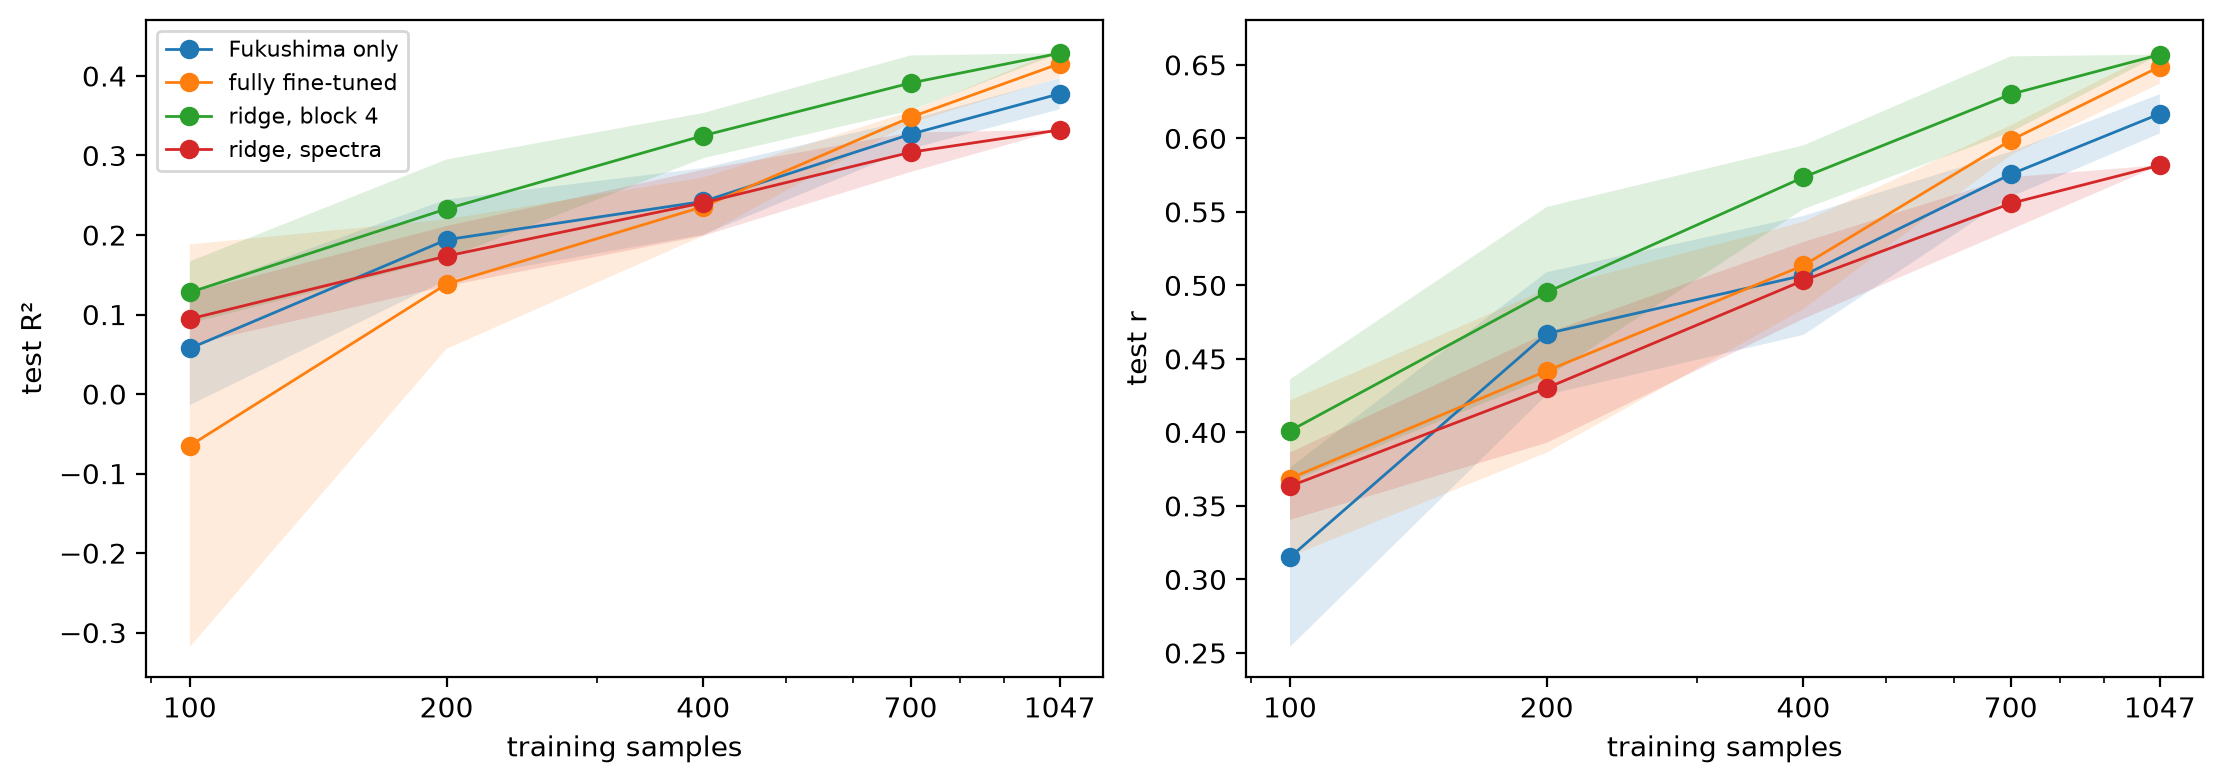

In [ ]:
#| fukudata
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), layout='constrained')
for ax, st in zip(axs, ('R²', 'r')):
    for m in summ.index.get_level_values(0).unique():
        s = summ.loc[m, st]
        ax.plot(s.index, s['mean'], marker='o', lw=1, label=m)
        ax.fill_between(s.index, s['mean'] - s['std'], s['mean'] + s['std'], alpha=0.15)
    ax.set_xscale('log'); ax.set_xticks(sizes, sizes); ax.set_xlabel('training samples'); ax.set_ylabel(f'test {st}')
axs[0].legend(fontsize=8);

The gain in mean R² per doubling of the training set, between consecutive sizes:

In [ ]:
#| fukudata
r2 = summ.xs('mean', axis=1, level=1)['R²'].unstack(0)
(r2.diff().div(np.log2(r2.index.to_series()).diff(), axis=0)).dropna().round(3)

model,Fukushima only,fully fine-tuned,"ridge, block 4","ridge, spectra"
n,,,,
200,0.137,0.203,0.105,0.079
400,0.048,0.097,0.092,0.067
700,0.105,0.139,0.082,0.079
1047,0.088,0.116,0.065,0.048


## Findings

No model reaches a plateau. Between 700 and 1,047 training samples, the mean test R² still rises by 0.05 to 0.12 per doubling of the training set: 0.116 for the fully fine-tuned CNN, 0.088 for the Fukushima-only CNN, 0.065 for the ridge regression on block 4 and 0.048 for the ridge regression on the spectra. With 1,047 samples, the Kex scores on Fukushima are limited by the number of samples. The curve doesn't show how far they would rise with more.

The frozen OSSL features help most when samples are few. The ridge regression on block 4 is the best model, or level with the best, at every size. At 400 samples it reaches an R² of 0.33 (r 0.57), against 0.24 for the Fukushima-only CNN, the fully fine-tuned CNN and the ridge regression on the spectra. At 1,047 samples the gap has closed: 0.43 for the ridge regression on block 4 and 0.42 for the fully fine-tuned CNN.

The fully fine-tuned CNN gains fastest from 400 samples upwards. It overtakes the Fukushima-only CNN from 700 samples (0.35 against 0.33) and leads it at 1,047 (0.42 against 0.38). At 100 samples it is unstable (R² −0.07, standard deviation 0.25 over the seeds), but its correlation (0.37) is higher than the Fukushima-only CNN's (0.32). The schedules were chosen for 1,047 samples and not retuned for smaller sizes, so the CNNs may be underrated at small sizes.

The ridge regression on the spectra, close to a PLSR baseline, gains least: 0.33 at 1,047 samples, rising by 0.05 per doubling.